# Week 1 EDA: the sampled application table

Work through the sections in order. Cells marked **PROVIDED** run as they are. For each
**TODO(student)** section, answer the question with code in the empty cell, then write one
or two sentences of what you see. Keep reusable code in `src/`; this notebook is for looking.

Run it from the repository root with `jupyter notebook` (or `jupyter lab`) after `python run.py sample`.

## 1. Load the sample  (PROVIDED)

In [1]:
# PROVIDED
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_application  # noqa: E402
from src.utils import load_config  # noqa: E402

config = load_config(ROOT / "config" / "config.yaml")
app = load_application(config)
print(app.shape)
app.head()

(5000, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100021,0,Revolving loans,F,N,Y,1,81000.0,270000.0,13500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,100030,0,Cash loans,F,N,Y,0,90000.0,225000.0,11074.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100033,0,Cash loans,M,Y,Y,0,270000.0,790830.0,57676.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
3,100294,0,Cash loans,F,N,Y,0,157500.0,835380.0,35392.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
4,100322,0,Cash loans,M,Y,Y,2,225000.0,254700.0,26874.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Target rate  (PROVIDED)

TARGET
0    4596
1     404
Name: count, dtype: int64
Default rate: 8.08%


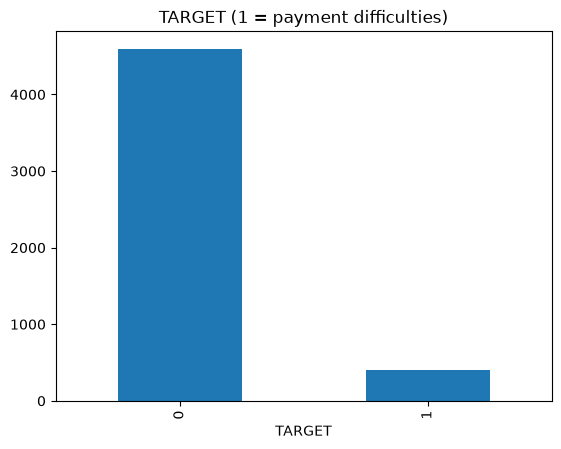

In [2]:
# PROVIDED
counts = app["TARGET"].value_counts().sort_index()
print(counts)
print(f"Default rate: {app['TARGET'].mean():.2%}")
counts.plot.bar(title="TARGET (1 = payment difficulties)")
plt.show()

## 3. Missingness  (TODO(student))

Which columns have the most missing values? How many columns are more than half empty?
Do the most-missing columns seem to belong together (look at their names)?

In [3]:
missing = app.isna().mean().sort_values(ascending=False) * 100

print(missing.head(15))
print("Columns more than half empty:", (missing > 50).sum())


COMMONAREA_AVG              71.42
COMMONAREA_MODE             71.42
COMMONAREA_MEDI             71.42
NONLIVINGAPARTMENTS_MEDI    71.02
NONLIVINGAPARTMENTS_MODE    71.02
NONLIVINGAPARTMENTS_AVG     71.02
LIVINGAPARTMENTS_AVG        70.16
LIVINGAPARTMENTS_MODE       70.16
LIVINGAPARTMENTS_MEDI       70.16
FONDKAPREMONT_MODE          70.08
FLOORSMIN_MODE              69.60
FLOORSMIN_AVG               69.60
FLOORSMIN_MEDI              69.60
YEARS_BUILD_AVG             68.10
YEARS_BUILD_MODE            68.10
dtype: float64
Columns more than half empty: 48


## 4. The DAYS_EMPLOYED anomaly  (TODO(student))

Look at the distribution of `DAYS_EMPLOYED`. Which value looks impossible, and how many
applicants have it? Is the default rate of those applicants different from everyone else's?
What does that tell you about how to handle it?

count      5000.000000
mean      63622.116200
std      141057.282676
min      -15202.000000
25%       -2686.750000
50%       -1198.000000
75%        -305.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64
Applicants with impossible value: 897
Default rate with anomaly: 4.91%
Default rate without anomaly: 8.77%


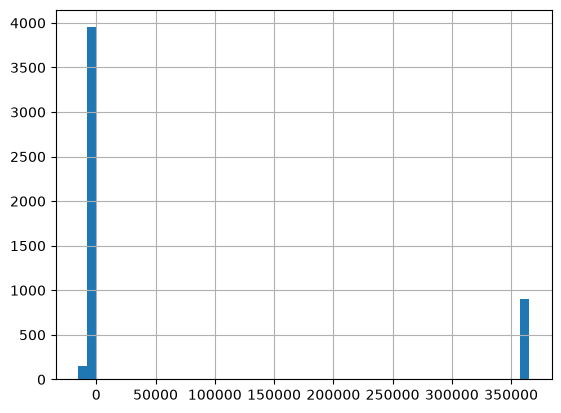

In [4]:
# TODO(student)
print(app["DAYS_EMPLOYED"].describe())

anomaly = app["DAYS_EMPLOYED"] == 365243

print("Applicants with impossible value:", anomaly.sum())
print("Default rate with anomaly:", f"{app.loc[anomaly, 'TARGET'].mean():.2%}")
print("Default rate without anomaly:", f"{app.loc[~anomaly, 'TARGET'].mean():.2%}")

app["DAYS_EMPLOYED"].hist(bins=50)
plt.show()

## 5. Default rate by a categorical column  (TODO(student))

Pick one categorical column (for example `NAME_CONTRACT_TYPE`, `CODE_GENDER`, or
`OCCUPATION_TYPE`). Show the default rate and the number of applicants in each category.
Which differences would you trust, given how few applicants some categories have?

In [5]:
# TODO(student)
category_summary = app.groupby("NAME_CONTRACT_TYPE")["TARGET"].agg(
    applicants="count",
    default_rate="mean"
)

category_summary["default_rate"] *= 100
print(category_summary)

                    applicants  default_rate
NAME_CONTRACT_TYPE                          
Cash loans                4525      8.441989
Revolving loans            475      4.631579


## 6. Correlations with TARGET  (TODO(student))

Which numeric columns are most correlated with `TARGET` (positively and negatively)?
Remember the sign conventions: `DAYS_*` columns are negative numbers of days before the
application. Is a correlation of 0.1 large or small here?

In [6]:
# TODO(student)
correlations = app.select_dtypes(include="number").corr()["TARGET"]
correlations = correlations.drop(["TARGET", "SK_ID_CURR"])

print("Most positive:")
print(correlations.sort_values(ascending=False).head(5))

print("\nMost negative:")
print(correlations.sort_values().head(5))


Most positive:
DAYS_BIRTH                     0.083414
REG_CITY_NOT_LIVE_CITY         0.067809
REG_CITY_NOT_WORK_CITY         0.066629
DAYS_LAST_PHONE_CHANGE         0.059441
REGION_RATING_CLIENT_W_CITY    0.057769
Name: TARGET, dtype: float64

Most negative:
EXT_SOURCE_2      -0.189234
EXT_SOURCE_1      -0.183445
EXT_SOURCE_3      -0.161417
DAYS_EMPLOYED     -0.053157
AMT_GOODS_PRICE   -0.052002
Name: TARGET, dtype: float64


## 7. Findings  (TODO(student))

Write 4 to 6 bullet points: what you learned and what it means for the baseline model.

- TODO(student)
* the sample has 5000 applicants and 8.08% had payment difficulties
* Predicting no payment difficulties for everyone would give 91.92% accuracy, so accuracy alone is misleading.
* About 25.1% of the application table’s cells are missing, so the baseline needs to fill missing values.
* DAYS_EMPLOYED contains an impossible placeholder value that needs to be replaced, with a flag to preserve that information.
* The data includes text categories, so the baseline needs to encode them before training.